# Program 23: Medical Lab Treatment Effectiveness & Hypothesis Testing

**Scenario / Problem Statement**

Determine whether treatment responses differ significantly between the treatment and placebo groups using an independent two-sample t-test.

Run the cells from top to bottom in Google Colab.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats


## 2. Upload and load the supplied dataset

Dataset loaded: FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q23_Clinical_Trial.csv
Shape: (80, 5)
T-Statistic: 4.4092
P-Value: 0.000033
The difference between groups is statistically significant.


,Patient_ID,Group,Baseline_Score,Post_Treatment_Score,Improvement
0,PT-001,Placebo,84.9,65.2,19.7
1,PT-002,Placebo,74.5,79.4,-4.9
2,PT-003,Placebo,77.9,81.2,-3.3
3,PT-004,Placebo,73.5,71.3,2.2
4,PT-005,Placebo,81.5,84.4,-2.9


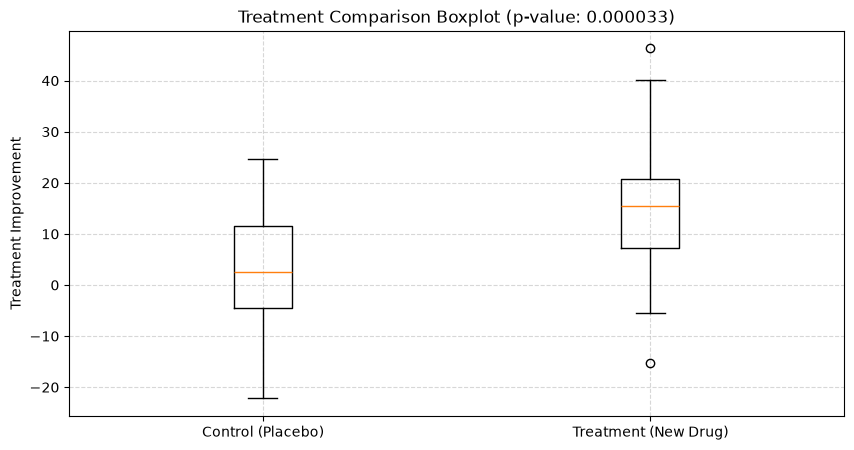

In [2]:
# Load the supplied CSV. In Colab, upload it if it is not already present.
from pathlib import Path
DATA_FILE = 'FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q23_Clinical_Trial.csv'
if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError as exc:
        raise FileNotFoundError('FODS_Lab_Datasets_Q20_to_Q40.xlsx - Q23_Clinical_Trial.csv is missing; place the CSV beside this notebook.') from exc
df_raw = pd.read_csv(DATA_FILE, skiprows=3)
print("Dataset loaded:", DATA_FILE)
print("Shape:", df_raw.shape)
display(df_raw.head())

# Compare improvement scores between the two independent groups
control_group = df_raw.loc[df_raw["Group"].str.lower().isin(["placebo", "control"]), "Improvement"].dropna()
treatment_group = df_raw.loc[df_raw["Group"].str.lower().isin(["treatment", "drug"]), "Improvement"].dropna()

t_stat, p_value = stats.ttest_ind(treatment_group, control_group, equal_var=False)

plt.figure(figsize=(10, 5))
plt.boxplot([control_group, treatment_group], tick_labels=["Control (Placebo)", "Treatment (New Drug)"])
plt.title(f"Treatment Comparison Boxplot (p-value: {p_value:.6f})")
plt.ylabel("Treatment Improvement")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.6f}")
if p_value < 0.05:
    print("The difference between groups is statistically significant.")
else:
    print("The difference is not statistically significant.")

## 3. Result

The output above displays the analysis, model evaluation, prediction, or visualization for this program.